In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Fetch UCI Heart Disease Dataset
heart_disease = fetch_ucirepo(id=45)

# Extract features and target
X = heart_disease.data.features.copy()
y = heart_disease.data.targets.copy()

# Display dataset
print("Dataset downloaded successfully!")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Dataset downloaded successfully!
Features shape: (303, 13)
Target shape: (303, 1)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


,num
0,0
1,2
2,1
3,0
4,0


In [3]:
#Combine features and target
df = X.copy()

df["num"] = y.iloc[:, 0].values

print("Complete Dataset:")
display(df.head())

print("\nDataset Shape:", df.shape)

Complete Dataset:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



Dataset Shape: (303, 14)


In [4]:
# Replace question marks with missing values
df = df.replace("?", np.nan)

# Convert columns to numeric
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove records with missing target
df = df.dropna(subset=["num"])

# Binary target conversion
df["target"] = (df["num"] > 0).astype(int)

# Remove original target
df = df.drop(columns=["num"])

print("Target converted successfully!")

print(df["target"].value_counts())
display(df.head())

Target converted successfully!
target
0    164
1    139
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [5]:
import os
import pandas as pd
import numpy as np

os.makedirs("../data", exist_ok=True)

df.to_csv("../data/heart_disease_1.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [6]:
print("Dataset Information")

print("\nShape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Information

Shape:
(303, 14)

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data Types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     3

In [7]:
display(df.describe())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


In [8]:
print("Missing Values:")

print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total Missing Values:
6


In [9]:
print("Duplicate Records:",
      df.duplicated().sum())

Duplicate Records: 0


In [10]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate check:", df.shape)

Shape after duplicate check: (303, 14)


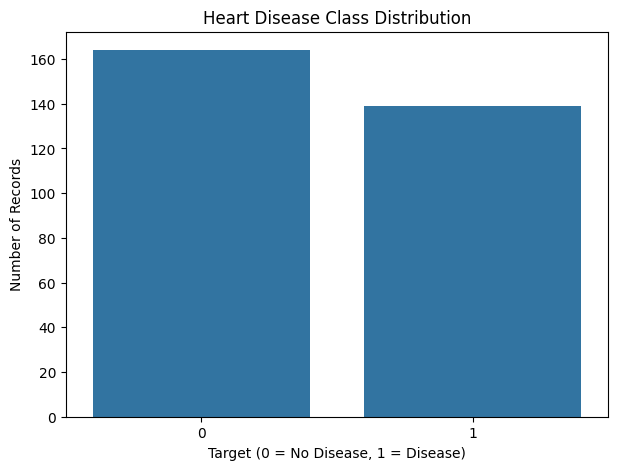

In [11]:
import matplotlib.pyplot as plt 
import seaborn as sns
import pandas as pd

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="target"
)

plt.title("Heart Disease Class Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Records")

plt.show()

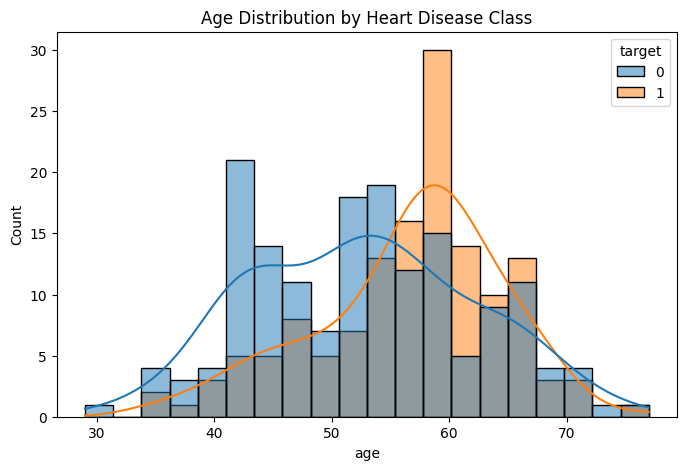

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue="target",
    kde=True,
    bins=20
)

plt.title("Age Distribution by Heart Disease Class")

plt.show()

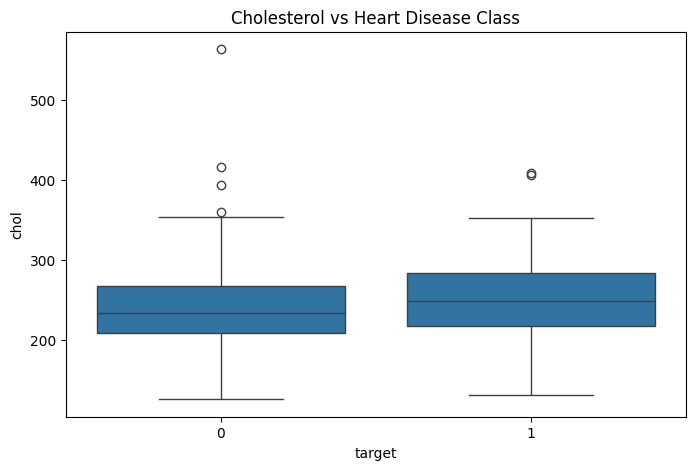

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="target",
    y="chol"
)

plt.title("Cholesterol vs Heart Disease Class")

plt.show()

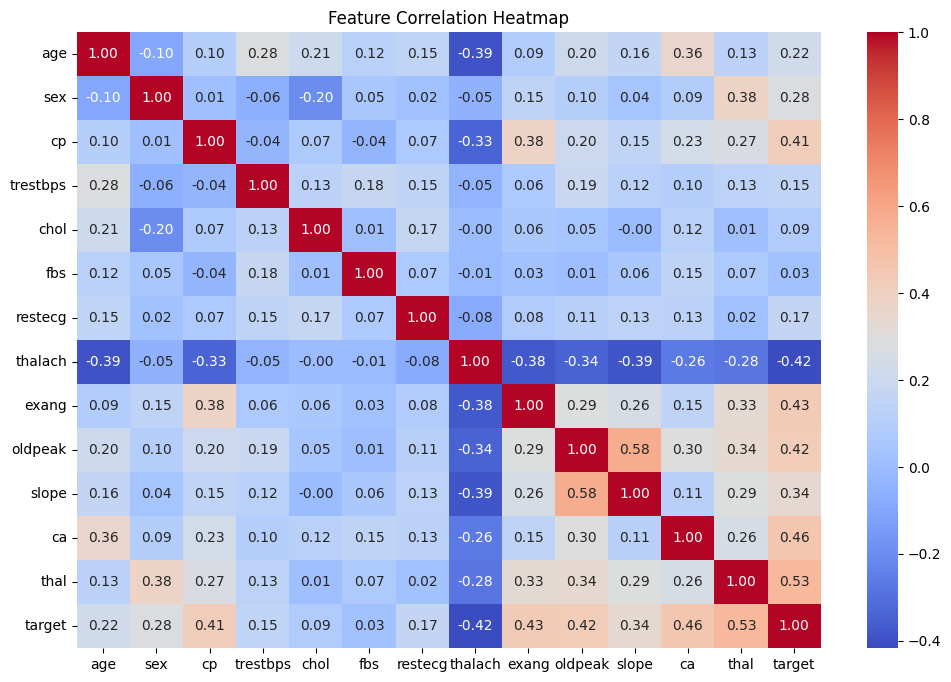

In [14]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [15]:
X = df.drop("target", axis=1)

y = df["target"]

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (303, 13)
Target: (303,)


In [16]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data: (242, 13)
Testing data: (61, 13)

Training target distribution:
target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.540984
1    0.459016
Name: proportion, dtype: float64


In [18]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced"
    ),

    "KNN": KNeighborsClassifier(),

    "Random Forest": RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "SVC": SVC(
        probability=True,
        class_weight="balanced"
    )
}

print("Four ML algorithms initialized!")

Four ML algorithms initialized!


In [20]:
pipelines = {}

for name, model in models.items():

    pipelines[name] = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

print("All model pipelines created!")

All model pipelines created!


In [21]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc"
}

results = []

for name, pipeline in pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean ROC-AUC": scores["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Mean ROC-AUC",
    ascending=False
)

display(results_df)

,Model,Mean Accuracy,Mean ROC-AUC
0,Logistic Regression,0.855187,0.902478
2,Random Forest,0.822279,0.891460
3,SVC,0.822109,0.887641
1,KNN,0.822194,0.871181


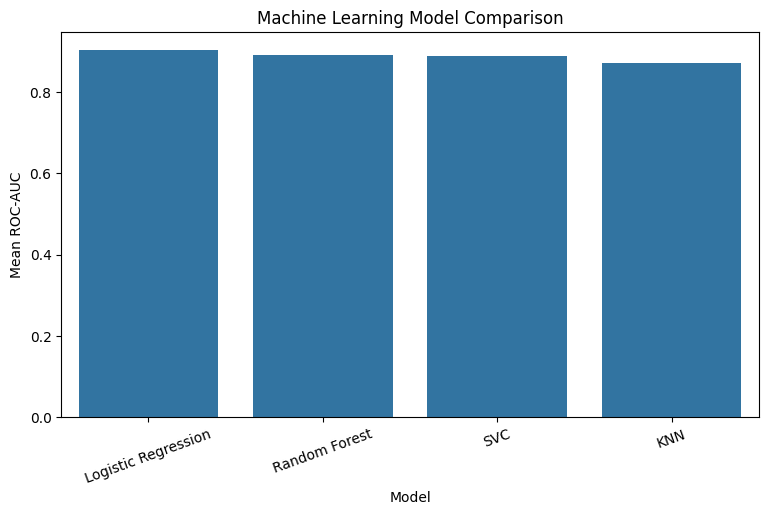

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Mean ROC-AUC"
)

plt.title("Machine Learning Model Comparison")
plt.xticks(rotation=20)

plt.show()

In [23]:
best_model_name = results_df.iloc[0]["Model"]

print("Selected model:", best_model_name)

best_model = models[best_model_name]

Selected model: Logistic Regression


In [24]:
param_grids = {

    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__solver": ["lbfgs", "liblinear"]
    },

    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 5, 10],
        "classifier__min_samples_split": [2, 5],
        "classifier__min_samples_leaf": [1, 2]
    },

    "SVC": {
        "classifier__C": [0.1, 1, 10],
        "classifier__kernel": ["linear", "rbf"],
        "classifier__gamma": ["scale", "auto"]
    }
}

In [25]:
from sklearn.model_selection import GridSearchCV

selected_pipeline = pipelines[best_model_name]

grid = GridSearchCV(
    estimator=selected_pipeline,
    param_grid=param_grids[best_model_name],
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

print("\nBest CV ROC-AUC:")
print(grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters:
{'classifier__C': 0.1, 'classifier__solver': 'liblinear'}

Best CV ROC-AUC:
0.9031400966183576


In [26]:
#Extract the best pipeline
best_pipeline = grid.best_estimator_

print("Best fitted pipeline:")
print(best_pipeline)

Best fitted pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   O

In [27]:
y_pred = best_pipeline.predict(X_test)

y_probability = best_pipeline.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [28]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 88.52 %


In [29]:
from sklearn.metrics import precision_score

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Precision:", round(precision, 4))

Precision: 0.8387


In [30]:
from sklearn.metrics import recall_score

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Recall:", round(recall, 4))

Recall: 0.9286


In [31]:
from sklearn.metrics import f1_score

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("F1 Score:", round(f1, 4))

F1 Score: 0.8814


In [32]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("ROC-AUC:", round(roc_auc, 4))

ROC-AUC: 0.9665


In [33]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Heart Disease",
            "Heart Disease Present"
        ],
        zero_division=0
    )
)

                       precision    recall  f1-score   support

     No Heart Disease       0.93      0.85      0.89        33
Heart Disease Present       0.84      0.93      0.88        28

             accuracy                           0.89        61
            macro avg       0.89      0.89      0.89        61
         weighted avg       0.89      0.89      0.89        61



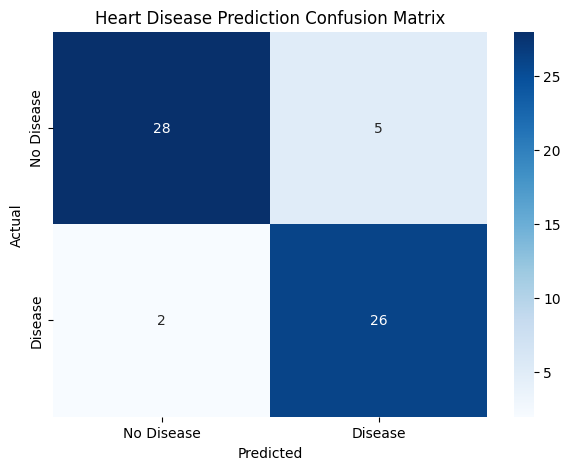

In [34]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Disease"],
    yticklabels=["No Disease", "Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Heart Disease Prediction Confusion Matrix")

plt.show()

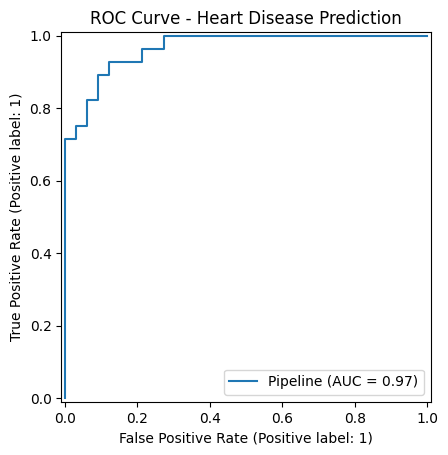

In [35]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    best_pipeline,
    X_test,
    y_test
)

plt.title("ROC Curve - Heart Disease Prediction")

plt.show()

In [36]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

display(final_results)

,Metric,Score
0,Accuracy,0.885246
1,Precision,0.838710
2,Recall,0.928571
3,F1 Score,0.881356
4,ROC-AUC,0.966450


In [37]:
import pickle
import os

os.makedirs("../models", exist_ok=True)

model_path = "../models/heart_disease_pipeline.pkl"

with open(model_path, "wb") as file:

    pickle.dump(
        best_pipeline,
        file
    )

print("Model saved successfully!")

Model saved successfully!


In [38]:
with open(model_path, "rb") as file:

    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [39]:
test_prediction = loaded_model.predict(
    X_test.iloc[[0]]
)

print("Actual:", y_test.iloc[0])

print("Predicted:", test_prediction[0])

Actual: 0
Predicted: 0
